# UroSentinel: explainable, ethics-by-design urology prediction
### Urology prediction model 2, version 3 · Prof Muthu Ramachandran, Forti5 Technologies Ltd

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Muthuuk/Urology-Sentinel/blob/main/notebooks/UroSentinel_Colab.ipynb)

> **Research prototype only. Not a medical device. It does not diagnose any condition.**

This notebook upgrades *Urology prediction model 2* (a Random Forest trained on one uploaded CSV) into a tool that is larger in scale, explainable, fair and interactive. It brings together the two ABH 2026 studies: deep learning with SHAP on NHANES for overactive bladder, and rough set-augmented ensembles for OAB versus IC/BPS.

| | Model 2 | UroSentinel (this notebook) |
|---|---|---|
| Data | one uploaded CSV | NHANES (US, several survey cycles, about 25,000 adults), UCI Acute Inflammations (Poland), UK data once access is approved, your own clinical CSV |
| Explanations | feature importance | SHAP and LIME for every prediction, checked against each other |
| Data accuracy | basic checks | ethics-by-design cleaning log, and rough set theory to find contradictory records |
| Uncertain cases | always given a label | rough set boundary triage: uncertain patients are referred |
| Fairness | none | audit by sex, age, ethnicity and income |
| Users | text prompts | patient screen, clinician screen, shareable web app |
| Governance | none | V-EGRCSbyD checklist, model card, clinician decision log |

**How to use:** choose **Runtime → Run all**. It takes about 5 to 10 minutes. Each part starts with a short plain-English explanation.

**Where to find the interactive tools:** the patient and clinician screens are at the **end of the notebook (Parts F and G)**. Open the table of contents (the list icon on the left) and click **Part F**, or scroll to the bottom once Run all has finished. Part G opens the same screens as a web app inside the notebook, and can also give a temporary link to share with colleagues.

## Setup
This downloads the UroSentinel code from GitHub and installs the libraries it needs.

In [1]:
import os, sys, subprocess, warnings
warnings.filterwarnings("ignore")
REPO = "https://github.com/Muthuuk/Urology-Sentinel.git"
if not os.path.exists("urosentinel"):
    if not os.path.exists("Urology-Sentinel"):
        subprocess.run(["git", "clone", "-q", REPO], check=True)
    else:  # a copy from an earlier run: fetch the latest fixes
        subprocess.run(["git", "-C", "Urology-Sentinel", "pull", "-q"], check=False)
    os.chdir("Urology-Sentinel")
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"], check=True)
sys.path.insert(0, os.getcwd())
try:
    from google.colab import output; output.enable_custom_widget_manager()
except Exception:
    pass

import numpy as np, pandas as pd, matplotlib.pyplot as plt, shap
from IPython.display import display, Markdown
from urosentinel import data_sources as ds, ethics, roughsets as rs, models as m, explain as ex, DISCLAIMER, __version__
pd.set_option("display.max_colwidth", 120)
print("UroSentinel version", __version__)

UroSentinel version 3.0.0


## Part 0. Ethics by design, before any data is touched

Ethics is built in from the start rather than checked at the end. The notebook follows the **V-EGRCSbyD** approach (Validation, Ethics, Governance, Risk, Compliance and Security by Design) and five widely used AI ethics principles:

- **Beneficence**: the tool should help people get the right care sooner.
- **Non-maleficence**: avoid harm, so missed cases are treated as the most serious error, and uncertain cases are referred rather than guessed.
- **Autonomy**: patients and clinicians stay in control. The tool suggests and the clinician decides, and that decision is recorded.
- **Justice**: the model must work fairly for women and men, older and younger people, and every ethnic and income group. Ethnicity and income are used only to check fairness, never as inputs.
- **Explicability**: every prediction comes with reasons (SHAP and LIME) and, where possible, a readable IF-THEN rule.

At the end of the notebook the V-EGRCSbyD checklist is filled in from evidence the code has produced.

## Part A. Population screening with NHANES (United States)

**NHANES** (the National Health and Nutrition Examination Survey) is a nationally representative US survey that combines interviews, examinations and laboratory tests. Its kidney and urology questions are asked in every cycle. We pool several cycles to get a large sample.

**What we predict:** an *OAB-wet proxy*: leaking urine before reaching the toilet, at least a few times a month. NHANES has no direct urgency question, so this is the closest honest stand-in. It is a screening label, not a diagnosis.

**Improvement on the ABH 2026 paper:** the questions used to build the label (urge leakage and how often leaks happen) are **completely removed from the inputs**, fixing the "partial feature overlap" limitation reported in that paper.

In [2]:
# Choose which NHANES cycles to pool. Each adds about 5,000 to 6,000 adults with urology answers.
CYCLES = ["2009-2010", "2011-2012", "2013-2014", "2015-2016", "2017-2018", "2021-2023"]
raw = ds.load_nhanes(CYCLES)
print(f"\nTotal participants: {len(raw):,}   Synthetic: {raw.attrs['synthetic']}")
if raw.attrs["synthetic"]:
    display(Markdown("**Warning: NHANES could not be downloaded, so a SYNTHETIC sample is being used. Do not report these numbers.**"))

  NHANES 2009-2010: 10,537 participants
  NHANES 2011-2012: 9,756 participants
  NHANES 2013-2014: 10,175 participants
  NHANES 2015-2016: 9,971 participants
  NHANES 2017-2018: 9,254 participants
  NHANES 2021-2023: 11,933 participants

Total participants: 61,626   Synthetic: False


### A1. Ethics-by-design cleaning
Each step below is logged with the principle it serves. Values that cannot be right are set to *missing* rather than guessed; filling in missing values happens later, inside the model, using training data only. Pregnant participants are excluded because bladder symptoms in pregnancy have a different cause, and children are excluded because the urology questions are for adults.

In [3]:
adults = raw[raw["age"] >= 20]
clean, log = ethics.ethical_clean(
    adults, valid_ranges={"age": (20, 120), "bmi": (12, 80), "nocturia": (0, 5)},
    id_cols=["seqn"], exclude_if={"pregnant": 1}, protected_features=ds.NHANES_AUDIT_ONLY)
clean = ds.add_nhanes_target(clean)
display(log.to_frame())
w = clean["survey_weight"].fillna(0)
lab = clean[ds.NHANES_TARGET]
print(f"Adults analysed: {lab.notna().sum():,}")
print(f"OAB-wet proxy: {lab.mean():.1%} of the sample, {np.average(lab.dropna(), weights=w[lab.notna()]):.1%} of the US adult population (weighted)")

,step,principle,rows_affected,detail
0,Checked for direct identifiers,Autonomy and privacy (UK GDPR data minimisation),0,none found
1,Removed exact duplicate records,Non-maleficence: inaccurate data leads to unsafe predictions,3,
2,Set out-of-range bmi to missing,Non-maleficence: inaccurate data leads to unsafe predictions,8,valid range 12 to 80
3,Excluded rows where pregnant = 1,Non-maleficence: use the model only for the people it was built for,356,outside intended use
4,High missingness in pregnant,Explicability: every change to the data is recorded and reported,29647,82% missing; treat results using it with caution
5,Protected characteristics kept for fairness audit only,Justice: the data and model must work fairly for all groups,0,"ethnicity, income_ratio"


Adults analysed: 29,742
OAB-wet proxy: 14.1% of the sample, 12.2% of the US adult population (weighted)


### A2. Who is in the data?
NHANES deliberately over-samples some groups so that they can be studied reliably. The **population share** column applies the survey weights, which restore the true national picture. The model is trained with these weights so it reflects the population rather than the sampling design.

In [4]:
clean["age_band"] = ethics.age_band(clean["age"])
display(ethics.representativeness(clean, ["sex", "age_band", "ethnicity"], "survey_weight"))

,characteristic,group,n,sample_share,population_share
0,sex,Female,18844,0.519,0.513
1,sex,Male,17441,0.481,0.487
2,age_band,40-59,11649,0.321,0.365
3,age_band,18-39,11379,0.314,0.356
4,age_band,60-74,9122,0.251,0.199
5,age_band,75+,4135,0.114,0.081
6,ethnicity,Non-Hispanic White,15726,0.433,0.644
7,ethnicity,Non-Hispanic Black,7152,0.197,0.113
8,ethnicity,Other or multiracial,4996,0.138,0.092
9,ethnicity,Mexican American,4666,0.129,0.084


### A3. Rough set check on data accuracy
Rough set theory groups people whose answers are identical. If identical people have different labels, the data cannot separate them: they form the **boundary region**. In a self-reported survey some of this is natural, so nothing is deleted here. The check tells us how much of the population can be classified with certainty from these inputs, and which inputs matter most (the **reduct**).

In [5]:
nh = clean.dropna(subset=[ds.NHANES_TARGET]).reset_index(drop=True)
nh_d = rs.discretise(nh[ds.NHANES_FEATURES], cuts=rs.NHANES_CUTS)
y_nh = nh[ds.NHANES_TARGET].astype(int)
beta = rs.RoughSet.suggested_beta(y_nh)          # set above the base rate, because the outcome is uncommon
R_nh = rs.RoughSet(nh_d, y_nh, beta=beta, min_size=20)
red = R_nh.quick_reduct()
print(f"Certainty threshold (beta): {beta}")
print(f"Reduct (most informative inputs, in order): {red}")
print(f"Share of adults in groups that are at least {beta:.0%} one way: {R_nh.dependency(red):.1%}")
print(f"Share in the boundary region (similar answers, mixed outcomes): {len(R_nh.boundary_region(red)) / len(nh):.1%}")
print("\nHighest-risk groups (identical answers on the reduct, at least 20 people):")
display(R_nh.risk_groups(red, positive="1", min_support=20).head(8))

Certainty threshold (beta): 0.929
Reduct (most informative inputs, in order): ['age', 'stress_leak', 'nocturia', 'bmi', 'female']
Share of adults in groups that are at least 93% one way: 46.3%
Share in the boundary region (similar answers, mixed outcomes): 53.7%

Highest-risk groups (identical answers on the reduct, at least 20 people):


,age,stress_leak,nocturia,bmi,female,rate,n
0,75+,1,3+,<25,1,0.692,52
1,75+,1,3+,25-29,0,0.667,21
2,60-74,1,3+,30+,0,0.660,50
3,75+,1,2,30+,1,0.656,93
4,75+,1,3+,25-29,1,0.652,66
5,75+,1,3+,30+,0,0.643,28
6,75+,1,3+,30+,1,0.635,85
7,60-74,1,3+,30+,1,0.632,261


### A4. Compare four model families fairly
Logistic regression (a simple baseline), random forest (the Model 2 approach), gradient boosting, and a neural network (the ABH 2026 deep learning approach) are compared using 5-fold cross-validation on the same data. For screening, the threshold is set so the model finds **at least 85% of true cases**, because a missed case is the most harmful error.

In [6]:
cmp = m.compare_binary(nh[ds.NHANES_FEATURES], nh[ds.NHANES_TARGET].astype(int), target_sensitivity=0.85)
display(cmp)
BEST = cmp.iloc[0]["model"]
print("Best by AUROC:", BEST)

,model,AUROC,AUPRC,sensitivity,specificity,precision,F1,Brier,missed_cases,false_alarms,threshold
0,logistic,0.833,0.453,0.85,0.655,0.288,0.430,0.170,629,8811,0.406
1,neural_network,0.833,0.452,0.85,0.648,0.284,0.426,0.096,629,8990,0.106
2,gradient_boosting,0.830,0.446,0.85,0.648,0.284,0.426,0.168,629,8989,0.414
3,random_forest,0.827,0.437,0.85,0.644,0.281,0.423,0.153,629,9100,0.371


Best by AUROC: logistic


### A5. Train the final model and test it once on held-out data
80% of adults train the model and 20% are kept aside and used only once, for this test. **AUROC** is the chance the model ranks a random person with symptoms above a random person without (0.5 is guessing, 1 is perfect). **Sensitivity** is the share of true cases found.

In [7]:
screen_model = m.train_binary(nh, ds.NHANES_FEATURES, ds.NHANES_TARGET, model=BEST,
                              weight_col="survey_weight", target_sensitivity=0.85)
pd.Series(screen_model.test_metrics, name="held-out test").to_frame()

,held-out test
AUROC,0.828
AUPRC,0.444
sensitivity,0.830
specificity,0.645
precision,0.277
F1,0.416
Brier,0.174
missed_cases,143.000
false_alarms,1814.000


### A6. Fairness audit
Does the model miss more cases in some groups than in others? Groups whose sensitivity is more than 10 points below the best group are flagged for review. Ethnicity and income ratio were never model inputs; they are used here only to check fairness.

In [8]:
idx_te = screen_model.test_index   # the held-out people, in test order
groups = pd.DataFrame({"sex": nh.loc[idx_te, "sex"].values,
                       "age_band": ethics.age_band(nh.loc[idx_te, "age"]).astype(str).values,
                       "ethnicity": nh.loc[idx_te, "ethnicity"].values,
                       "income": pd.cut(nh.loc[idx_te, "income_ratio"], [-1, 1.3, 3.5, 99], labels=["low", "middle", "high"]).astype(str).values})
pred = (screen_model.test_prob >= screen_model.threshold).astype(int)
fair_nh = ethics.fairness_audit(screen_model.y_test, pred, screen_model.test_prob, groups)
display(fair_nh)

,characteristic,group,n,cases,sensitivity,precision,auroc,note
0,sex,Female,3039,598,0.898,0.284,0.783,
1,sex,Male,2910,241,0.660,0.256,0.852,REVIEW: misses more cases than the best group
2,age_band,18-39,1864,74,0.527,0.206,0.876,REVIEW: misses more cases than the best group
3,age_band,75+,634,196,0.980,0.327,0.730,
4,age_band,60-74,1557,357,0.852,0.288,0.734,REVIEW: misses more cases than the best group
5,age_band,40-59,1894,212,0.759,0.238,0.790,REVIEW: misses more cases than the best group
6,ethnicity,Other or multiracial,713,62,0.758,0.228,0.862,REVIEW: misses more cases than the best group
7,ethnicity,Non-Hispanic White,2661,431,0.872,0.302,0.829,
8,ethnicity,Other Hispanic,626,87,0.828,0.258,0.808,
9,ethnicity,Non-Hispanic Black,1149,150,0.747,0.241,0.784,REVIEW: misses more cases than the best group


### A7. Explainability: SHAP for the whole population
Each dot is one person. Dots to the right pushed that person's prediction up; colour shows whether their value was high (red) or low (blue). This shows which factors drive the model overall, and in which direction.

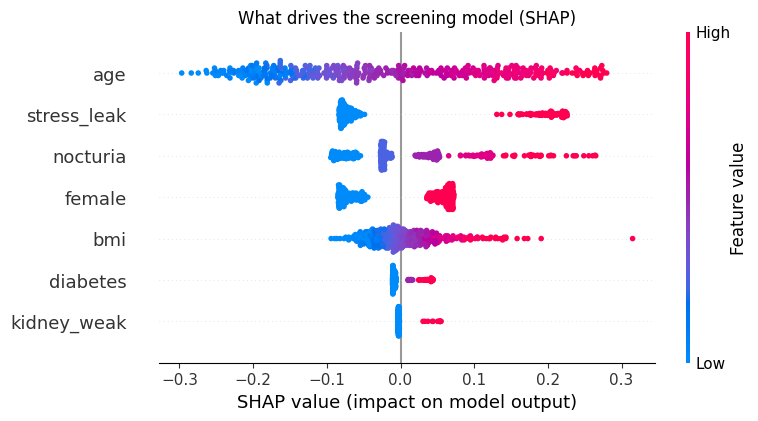

In [9]:
sv = ex.shap_explain(screen_model, screen_model.X_test.sample(400, random_state=0))
shap.plots.beeswarm(sv, show=False); plt.title("What drives the screening model (SHAP)"); plt.show()

### A8. Explaining one person, and checking SHAP against LIME
SHAP and LIME work in completely different ways. When they agree on the main reasons for a prediction, we can trust the explanation more. Below is one person's explanation, then the average agreement over 30 people.

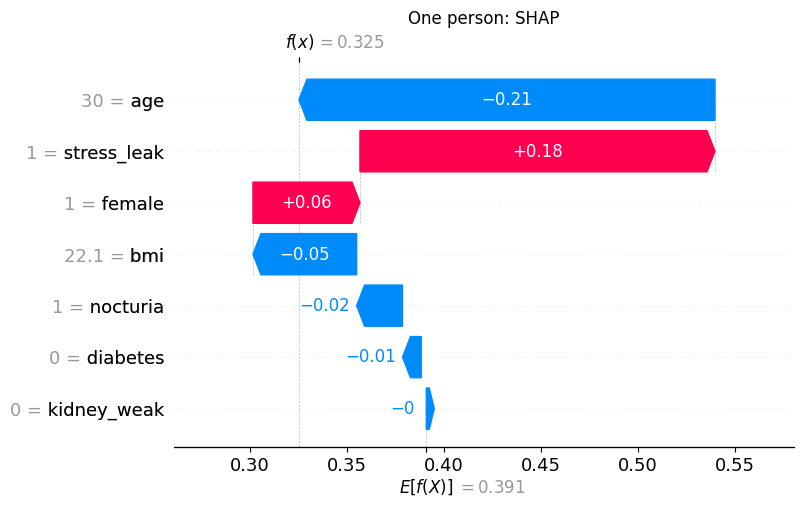

LIME reasons:
  stress_leak > 0.00: +0.271
  age <= 36.00: -0.255
  0.00 < female <= 1.00: +0.137
  bmi <= 24.60: -0.083
  diabetes <= 0.00: -0.040
  0.00 < nocturia <= 1.00: -0.026

SHAP and LIME agree on 83% of the top 3 reasons, on average over 30 people.


In [10]:
person = screen_model.X_test.iloc[[0]]
e1 = ex.shap_explain(screen_model, person)
shap.plots.waterfall(e1[0], show=False); plt.title("One person: SHAP"); plt.show()
lime_list, lime_exp = ex.lime_explain(screen_model, person)
print("LIME reasons:"); [print(f"  {c}: {v:+.3f}") for c, v in lime_list]
agree = []
for i in range(30):
    r = screen_model.X_test.iloc[[i]]
    agree.append(ex.agreement(ex.top_features_shap(ex.shap_explain(screen_model, r), k=3),
                              ex.lime_explain(screen_model, r)[0], screen_model.features))
print(f"\nSHAP and LIME agree on {np.mean(agree):.0%} of the top 3 reasons, on average over 30 people.")

## Part B. International data: UCI Acute Inflammations (Poland)

A small, public clinical dataset of 120 patients, labelled for **inflammation of the urinary bladder** and **nephritis of renal pelvis origin**. It was originally created to test a rough set expert system, so it is a fitting check of the rough set method on real clinical data from outside the US. Classical (crisp) rough sets are used because the data is small and clean.

In [11]:
uci = ds.load_uci_acute_inflammations()
if uci is not None:
    uci_d = rs.discretise(uci.drop(columns=["bladder_inflammation", "nephritis"]),
                          cuts={"temperature": ([0, 37.5, 38.5, 50], ["normal", "raised", "high"])})
    for target in ["bladder_inflammation", "nephritis"]:
        R_u = rs.RoughSet(uci_d, uci[target].astype(int), beta=1.0, min_size=1)
        red_u = R_u.quick_reduct()
        print(f"\n{target}: certainty from all features {R_u.dependency(R_u.attributes):.0%}; reduct {red_u}; core {R_u.core(red_u)}")
        for r in R_u.rules(red_u, min_support=5)[:4]:
            print("  ", r)
else:
    print("Skipped (offline).")

  UCI Acute Inflammations: 120 patients

bladder_inflammation: certainty from all features 100%; reduct ['urine_pushing', 'micturition_pain', 'lumbar_pain']; core ['urine_pushing', 'micturition_pain', 'lumbar_pain']
   IF urine_pushing = 1 AND micturition_pain = 1 AND lumbar_pain = 0 THEN 1  (certainty 1.00, support 30, coverage 50.8%)
   IF urine_pushing = 1 AND micturition_pain = 0 AND lumbar_pain = 1 THEN 0  (certainty 1.00, support 21, coverage 34.4%)
   IF urine_pushing = 0 AND micturition_pain = 0 AND lumbar_pain = 1 THEN 0  (certainty 1.00, support 20, coverage 32.8%)
   IF urine_pushing = 1 AND micturition_pain = 1 AND lumbar_pain = 1 THEN 1  (certainty 1.00, support 19, coverage 32.2%)

nephritis: certainty from all features 100%; reduct ['temperature', 'lumbar_pain', 'urine_pushing']; core ['temperature', 'lumbar_pain', 'urine_pushing']
   IF temperature = high AND lumbar_pain = 1 AND urine_pushing = 1 THEN 1  (certainty 1.00, support 35, coverage 70.0%)
   IF temperature = n

## Part C. Clinical differential: the six-condition model (Model 2, upgraded)

This continues Model 2: overactive bladder, IC/BPS, acute cystitis, chronic or recurrent cystitis, neurogenic bladder, and bladder outlet obstruction from prostate enlargement.

**Your data:** set `CLINICAL_CSV` to your own file in the Model 2 layout (upload it with the folder icon on the left). If it is left empty, a **synthetic** cohort is used so you can see how everything works. Results on synthetic data show the method works, not how well it would work on patients.

In [12]:
CLINICAL_CSV = ""   # for example "/content/my_bladder_data.csv"
clin_raw = ds.load_model2_csv(CLINICAL_CSV) if CLINICAL_CSV else ds.generate_clinical_cohort()
print(f"{len(clin_raw)} records. Synthetic: {clin_raw.attrs['synthetic']}")
clin, clog = ethics.ethical_clean(
    clin_raw, id_cols=["Patient_ID"],
    valid_ranges={"Age": (18, 110), **{c: (0, 10) for c in ["Frequency_Score", "Urgency_Score", "Nocturia_Score", "Pain_Score", "QoL_Impact_Score"]},
                  "PVR_ml": (0, 1500), "Duration_Months": (0, 600)})
display(clog.to_frame())

1820 records. Synthetic: True


,step,principle,rows_affected,detail
0,Checked for direct identifiers,Autonomy and privacy (UK GDPR data minimisation),0,none found
1,Removed exact duplicate records,Non-maleficence: inaccurate data leads to unsafe predictions,13,
2,Set out-of-range Age to missing,Non-maleficence: inaccurate data leads to unsafe predictions,3,valid range 18 to 110
3,Set out-of-range Pain_Score to missing,Non-maleficence: inaccurate data leads to unsafe predictions,6,valid range 0 to 10


### C1. Rough sets for data accuracy
Records with identical (banded) features but **different diagnoses** are listed. Some disagreement is genuine clinical uncertainty, for example the overlap between OAB and IC/BPS. But a record that disagrees with a **clear majority** of identical records is likely to be mislabelled. These are removed from **training only** (never from testing), and the list is kept so a clinician can review it.

In [13]:
feat = [c for c in ds.CLINICAL_FEATURES if clin[c].notna().any()]
clin_d = rs.discretise(clin[feat], cuts=rs.CLINICAL_CUTS)
R = rs.RoughSet(clin_d, clin["Primary_Diagnosis"], beta=0.85, min_size=3)
inc = R.inconsistent_records()
keep = R.accuracy_filter(min_group=3, min_majority=0.75)
print(f"Records in contradictory groups: {len(inc)}. Likely mislabelled (removed from training): {len(clin) - len(keep)}")
display(inc.merge(clin[["Patient_ID"]], left_on="row", right_index=True).head(10))   # likely mislabelled shown first

Records in contradictory groups: 49. Likely mislabelled (removed from training): 3


,row,label,majority_label,majority_share,group_size,disagrees_with_majority,Patient_ID
0,1415,BOO_BPH,OAB,0.900,10,True,SYN01415
1,11,Chronic_Cystitis,IC_BPS,0.750,4,True,SYN00011
2,1803,Acute_Cystitis,BOO_BPH,0.750,4,True,SYN00208-B
3,1804,Acute_Cystitis,Chronic_Cystitis,0.667,3,True,SYN01657-B
4,705,OAB,IC_BPS,0.500,2,True,SYN00705
5,941,IC_BPS,Chronic_Cystitis,0.500,2,True,SYN00941
6,977,Chronic_Cystitis,IC_BPS,0.500,2,True,SYN00977
7,1018,Chronic_Cystitis,IC_BPS,0.500,2,True,SYN01018
8,1159,OAB,IC_BPS,0.500,2,True,SYN01159
9,1172,IC_BPS,Chronic_Cystitis,0.500,2,True,SYN01172


### C2. Reduct, core and rules
The **reduct** is the smallest set of features that keeps almost all the power to tell the conditions apart. The **core** contains the features that cannot be dropped without losing that power. **Rules** are transparent IF-THEN statements that a clinician can check and a patient can follow.

In [14]:
reduct = R.quick_reduct()
print(f"{len(feat)} features reduced to {len(reduct)}: {reduct}")
print(f"Core: {R.core(reduct)}")
print(f"Patients classified with at least 85% certainty: {R.dependency(reduct):.0%}; boundary (refer): {len(R.boundary_region(reduct)) / len(clin):.0%}")
print("\nTop rules:")
for r in R.rules(reduct, min_support=10, min_certainty=0.9)[:8]:
    print(" ", r)

16 features reduced to 6: ['Duration_Months', 'Pain_Score', 'Neuro_History', 'PVR_ml', 'Recurrent_UTI_Count', 'Nitrite_Positive']
Core: ['Duration_Months', 'Pain_Score', 'Neuro_History', 'PVR_ml', 'Recurrent_UTI_Count']
Patients classified with at least 85% certainty: 78%; boundary (refer): 22%

Top rules:
  IF Duration_Months = >12m AND Pain_Score = high AND Neuro_History = 0 AND PVR_ml = <100 AND Recurrent_UTI_Count = 0 AND Nitrite_Positive = 0 THEN IC_BPS  (certainty 1.00, support 105, coverage 35.0%)
  IF Duration_Months = <1m AND Pain_Score = mid AND Neuro_History = 0 AND PVR_ml = <100 AND Recurrent_UTI_Count = 0 AND Nitrite_Positive = 1 THEN Acute_Cystitis  (certainty 1.00, support 86, coverage 28.1%)
  IF Duration_Months = <1m AND Pain_Score = mid AND Neuro_History = 0 AND PVR_ml = <100 AND Recurrent_UTI_Count = 1-2 AND Nitrite_Positive = 1 THEN Acute_Cystitis  (certainty 1.00, support 49, coverage 16.0%)
  IF Duration_Months = 1-12m AND Pain_Score = mid AND Neuro_History = 0 AN

### C3. Does rough set cleaning help? A fair comparison
The same model is trained four ways and tested on the same untouched test set: all features or the reduct only, each with and without the rough set accuracy filter. The benefit depends on how much labelling noise the data contains, so this is measured rather than assumed. With far fewer features the reduct is cheaper to collect and easier to explain; the table shows how much accuracy, if any, that costs.

In [15]:
res = []
for fs_name, fs in [("all features", feat), ("reduct only", reduct)]:
    for filt_name, kr in [("no filter", None), ("RST filter", keep)]:
        t = m.train_multiclass(clin, fs, "Primary_Diagnosis", keep_rows=kr)
        res.append({"features": fs_name, "training data": filt_name, "n features": len(fs), **t.test_metrics})
display(pd.DataFrame(res))

,features,training data,n features,accuracy,balanced_accuracy,macro_F1,macro_AUROC
0,all features,no filter,16,0.958,0.958,0.958,0.995
1,all features,RST filter,16,0.958,0.958,0.958,0.995
2,reduct only,no filter,6,0.909,0.909,0.909,0.986
3,reduct only,RST filter,6,0.909,0.909,0.909,0.987


### C4. Final clinical model and its explanations
SHAP shows, for each condition, which features push the prediction towards it.

{'accuracy': 0.958, 'balanced_accuracy': np.float64(0.958), 'macro_F1': 0.958, 'macro_AUROC': np.float64(0.995)}


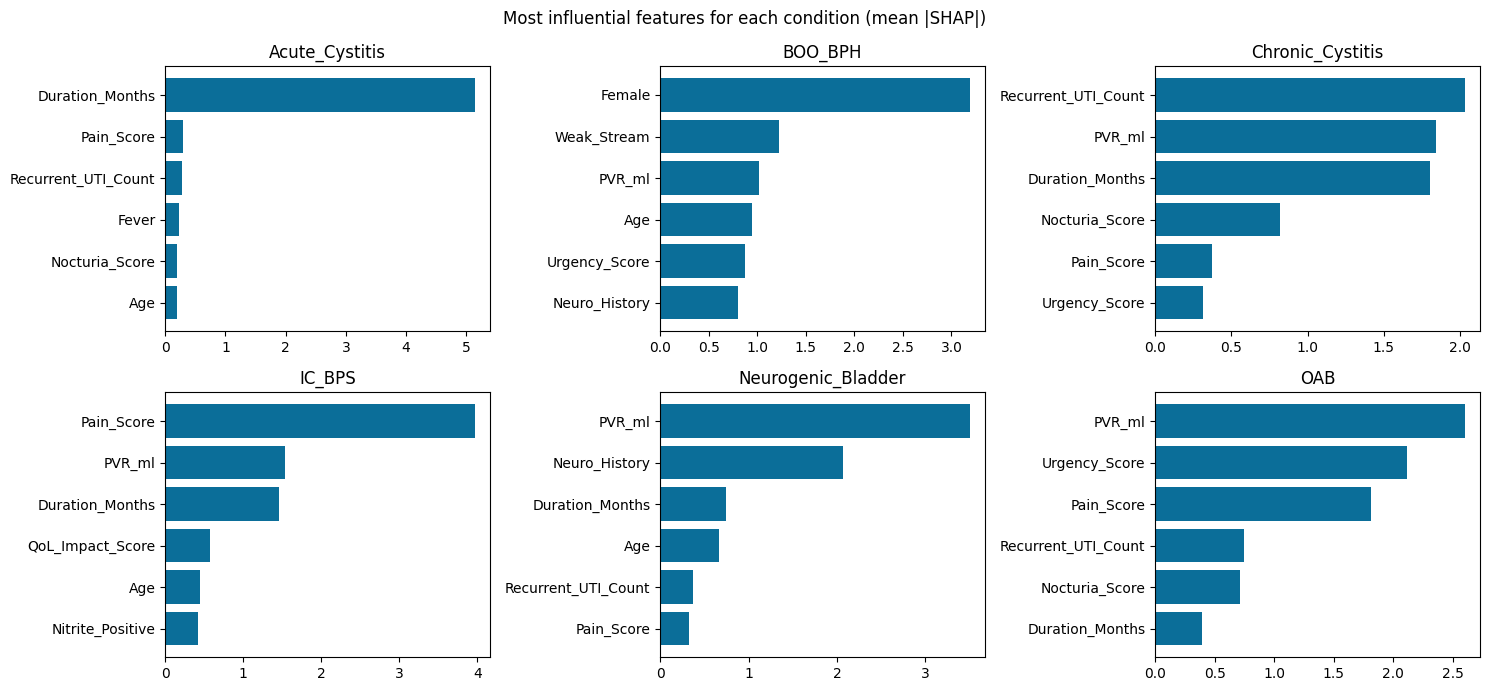

In [16]:
clin_model = m.train_multiclass(clin, feat, "Primary_Diagnosis", keep_rows=keep)
print(clin_model.test_metrics)
cls = list(clin_model.classes)
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
sample = clin_model.X_test.sample(200, random_state=0)
for k, ax in zip(range(len(cls)), axes.ravel()):
    e = ex.shap_explain(clin_model, sample, class_index=k)
    imp = pd.Series(np.abs(e.values).mean(0), index=feat).sort_values().tail(6)
    ax.barh(imp.index, imp.values, color="#0B6E99"); ax.set_title(cls[k])
plt.suptitle("Most influential features for each condition (mean |SHAP|)"); plt.tight_layout(); plt.show()

## Part D. UK data (plug in once access is approved)

UK Biobank, CPRD, OpenSAFELY and local NHS audits all need approved access, so nothing is downloaded. When you have approval, export an anonymised CSV with the columns below and set `UK_CSV`. The NHANES-trained model is then tested on UK data (**external validation**: does a model built in one country work in another?) and the fairness audit is repeated.

In [17]:
print(ds.UK_GUIDANCE)
UK_CSV = ""   # for example "/content/uk_extract.csv"
uk_result = None
if UK_CSV:
    uk = ds.add_nhanes_target(ds.load_uk_harmonised(UK_CSV, "UK dataset"))
    uk, uk_log = ethics.ethical_clean(uk, valid_ranges={"age": (20, 120), "bmi": (12, 80)})
    uk_result = m.external_validation(screen_model, uk, ds.NHANES_TARGET)
    display(pd.Series(uk_result, name="UK external validation").to_frame())

UK data needs approved access, so UroSentinel never downloads it.
  - UK Biobank: apply at ukbiobank.ac.uk (approved researchers, analysis in its Research Analysis Platform)
  - CPRD (primary care records): apply through the CPRD research data governance process
  - OpenSAFELY: code runs inside the platform; only aggregate results leave
  - Local NHS audit: needs Caldicott Guardian approval and a DPIA
Export an anonymised CSV with these columns, then call load_uk_harmonised(path):
  age, sex, bmi, diabetes, kidney_weak, stress_leak, urge_leak, leak_freq, nocturia
  Optional: ethnicity, income_ratio or IMD_decile (deprivation), survey_weight, source
Coding: sex Male/Female; yes/no as 1/0; diabetes 1/0.5/0; leak_freq 0 (never) to 4 (daily);
nocturia 0 to 5 (times per night, 5 = 5 or more).


## Part E. Governance: V-EGRCSbyD checklist and model cards
The checklist is filled in from evidence produced above. Items marked *Not yet* are the work needed before any clinical use.

In [18]:
checklist = ethics.vegrcs_checklist({
    "validated": True, "external_validation": uk_result is not None, "cleaning_log": log,
    "fairness_flags": fair_nh, "explainability": True, "provenance": raw.attrs.get("provenance"),
    "human_oversight": True, "rough_set": True, "synthetic": clin_raw.attrs["synthetic"],
    "protected_excluded": not set(ds.NHANES_AUDIT_ONLY) & set(ds.NHANES_FEATURES)})
display(checklist)

card_nh = ethics.model_card(
    "UroSentinel population screening (OAB-wet proxy)",
    "Flag adults who may have urgency urinary incontinence, so they can be encouraged to seek help.",
    raw.attrs, screen_model.test_metrics, fair_nh, ds.NHANES_FEATURES,
    ["urge leakage and leak frequency (used in the label)"] + ds.NHANES_AUDIT_ONLY,
    ["Self-reported survey answers, not clinical diagnoses.", "NHANES is cross-sectional (one point in time).",
     "Trained on US data; UK external validation is still needed.", "No direct urgency question in NHANES; a proxy label is used."],
    __version__)
card_cl = ethics.model_card(
    "UroSentinel clinical differential (six conditions)",
    "Support clinicians in considering a differential diagnosis for lower urinary tract symptoms.",
    clin_raw.attrs, clin_model.test_metrics, None, feat, [],
    ["Must be validated on real multicentre clinical data before any use.",
     "Rough set thresholds (beta = 0.85, minimum group size 3) were set by judgement and should be tuned on real data."],
    __version__)
open("MODEL_CARD_screening.md", "w").write(card_nh); open("MODEL_CARD_clinical.md", "w").write(card_cl)
display(Markdown(card_nh))

,V-EGRCSbyD area,requirement,met
0,Validation,Model tested on held-out data with clinically relevant measures,Yes
1,Validation,Tested on data from another country or setting (external validation),Not yet
2,Ethics,Data cleaning logged with the principle each step serves,Yes
3,Ethics,Fairness audit run; groups with lower sensitivity flagged,Yes
4,Ethics,Explanations available for every prediction (SHAP and LIME),Yes
5,Governance,Data sources and their licences recorded,Yes
6,Governance,"Clinician can accept or override the suggestion, and this is logged",Yes
7,Risk,"Uncertain cases are referred, not forced into a label (rough set boundary)",Yes
8,Risk,Results on synthetic data are labelled as such,Yes
9,Compliance,Protected characteristics excluded from model inputs,Yes


# Model card: UroSentinel population screening (OAB-wet proxy)

**Version:** 3.0.0  |  **Date:** 2026-11-23

## What it is for
Flag adults who may have urgency urinary incontinence, so they can be encouraged to seek help.

**Not for:** diagnosing anyone, or replacing a clinician's judgement. Research prototype only.

## Data
- NHANES 2009-2010 (CDC, public): DEMO, KIQ_U, DIQ, BMX
- NHANES 2011-2012 (CDC, public): DEMO, KIQ_U, DIQ, BMX
- NHANES 2013-2014 (CDC, public): DEMO, KIQ_U, DIQ, BMX
- NHANES 2015-2016 (CDC, public): DEMO, KIQ_U, DIQ, BMX
- NHANES 2017-2018 (CDC, public): DEMO, KIQ_U, DIQ, BMX
- NHANES 2021-2023 (CDC, public): DEMO, KIQ_U, DIQ, BMX



## Inputs
age, female, bmi, diabetes, kidney_weak, stress_leak, nocturia

Deliberately **not** used as inputs: urge leakage and leak frequency (used in the label), ethnicity, income_ratio

## Performance (held-out test data)
- AUROC: 0.828
- AUPRC: 0.444
- sensitivity: 0.83
- specificity: 0.645
- precision: 0.277
- F1: 0.416
- Brier: 0.174
- missed_cases: 143
- false_alarms: 1814

## Fairness check
- sex = Male: sensitivity 0.66
- age_band = 18-39: sensitivity 0.527
- age_band = 60-74: sensitivity 0.852
- age_band = 40-59: sensitivity 0.759
- ethnicity = Other or multiracial: sensitivity 0.758
- ethnicity = Non-Hispanic Black: sensitivity 0.747
- income = low: sensitivity 0.809
- income = high: sensitivity 0.804

## Known limitations
- Self-reported survey answers, not clinical diagnoses.
- NHANES is cross-sectional (one point in time).
- Trained on US data; UK external validation is still needed.
- No direct urgency question in NHANES; a proxy label is used.


### Save the trained models
This saves both models, so they can be reloaded without retraining. In Colab, the files can then be downloaded from the folder panel on the left.

In [19]:
from urosentinel.service import ScreeningService, ClinicalService
# the services wrap each model with its safety rules, explanations and advice; they are also used by Parts F and G
screening = ScreeningService(screen_model)
clinical = ClinicalService(clin_model, R, rs.CLINICAL_CUTS)
import joblib
joblib.dump({"screening": screening, "clinical": clinical, "version": __version__}, "urosentinel_models.joblib")
print("Saved urosentinel_models.joblib, MODEL_CARD_screening.md and MODEL_CARD_clinical.md")

Saved urosentinel_models.joblib, MODEL_CARD_screening.md and MODEL_CARD_clinical.md


## Part F. Interactive screens for patients and clinicians

Run the two cells below (they run automatically with Run all). Change any answer and press the button to see the result update.

**Patient screen:** plain-language questions, a likelihood band, the main reasons and practical next steps. Nothing is stored.

**Clinician screen:** full inputs; probabilities for each condition; rough set triage (refer when similar past patients had different diagnoses); red-flag safety checks that override the model; SHAP and LIME charts; a guideline pointer; a downloadable report; and a box to **record your own decision**, so a human always has the final say and every decision is auditable.

In [20]:
from urosentinel.service import ScreeningService, ClinicalService
from urosentinel.app import patient_screen, clinician_screen
screening = ScreeningService(screen_model)
clinical = ClinicalService(clin_model, R, rs.CLINICAL_CUTS)
display(patient_screen(screening))

In [21]:
display(clinician_screen(clinical))

## Part G. Web app inside the notebook (and an optional shareable link)

The cell below installs Gradio (about 30 seconds) and opens the same patient and clinician screens as a small web app with two tabs, shown directly below the cell. To let colleagues try it from their own browser, set `SHARE_LINK = True`: Gradio then prints a temporary public link (about 72 hours). **Do not enter real patient data into a shared link.**

In [22]:
SHARE_LINK = True   # True gives a temporary public link for demonstrations and usability testing
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "gradio"], check=True)
from urosentinel.gradio_app import build_app
web_app = build_app(screening, clinical)
web_app.launch(share=SHARE_LINK, inline=True, height=900)


Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://7d174ca46f5aa13cdb.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


---
**References:** NHANES (CDC National Center for Health Statistics); UCI Machine Learning Repository, Acute Inflammations dataset; Lundberg and Lee (2017), SHAP; Ribeiro et al. (2016), LIME; Pawlak (1982), rough sets; Ziarko (1993), variable precision rough sets; Subbiah and Ramachandran (ABH 2026); Ramachandran and Kavitha (ABH 2026); Ramachandran (2026), *Engineering Ethics of AI by Design*, Springer.